In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path(
    r"C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis"
)

(output_dir / "data" / "processed").mkdir(
    parents=True, exist_ok=True
)

(output_dir / "visualizations").mkdir(
    parents=True, exist_ok=True
)

print("India-US comparison environment ready!")

India-US comparison environment ready!


In [4]:
comparison_data = pd.DataFrame({
    "Country": ["India", "United States"],

    "Central_Bank": [
        "Reserve Bank of India",
        "Federal Reserve"
    ],

    "Inflation_Target_Percent": [4.0, 2.0],

    "Inflation_Target_Band": [
        "2%–6%",
        "2% long-run goal"
    ],

    "Billionaires_2024": [200, 813],
    "Billionaires_2025": [205, 902],

    "Happiness_Rank_2025": [118, 24]
})

comparison_data["Billionaire_Growth_Percent"] = (
    (comparison_data["Billionaires_2025"] -
     comparison_data["Billionaires_2024"])
    / comparison_data["Billionaires_2024"] * 100
)

display(comparison_data)

,Country,Central_Bank,Inflation_Target_Percent,Inflation_Target_Band,Billionaires_2024,Billionaires_2025,Happiness_Rank_2025,Billionaire_Growth_Percent
0,India,Reserve Bank of India,4.0,2%–6%,200,205,118,2.500000
1,United States,Federal Reserve,2.0,2% long-run goal,813,902,24,10.947109


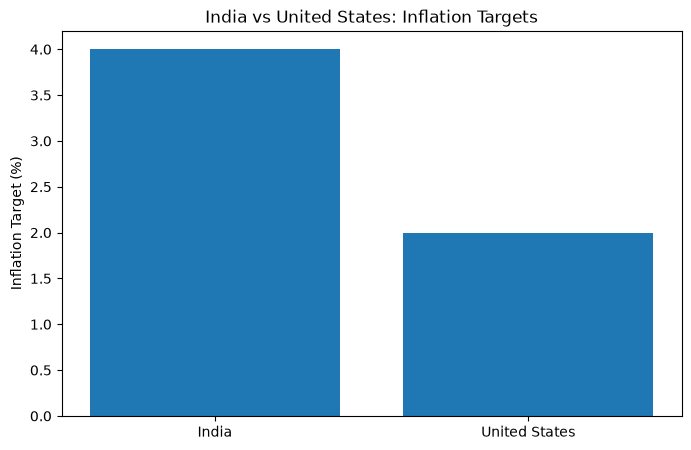

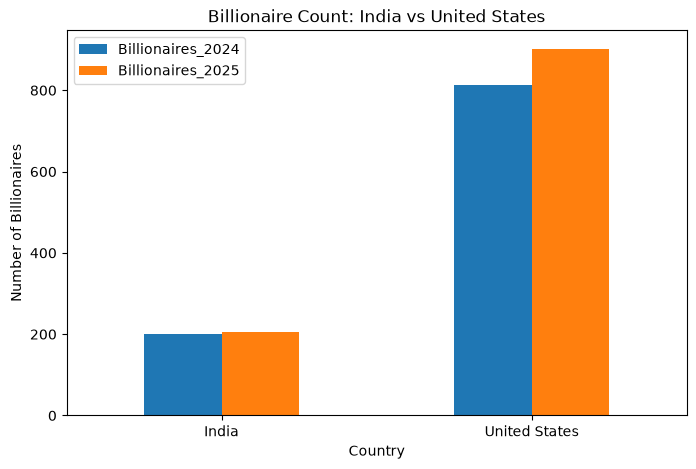

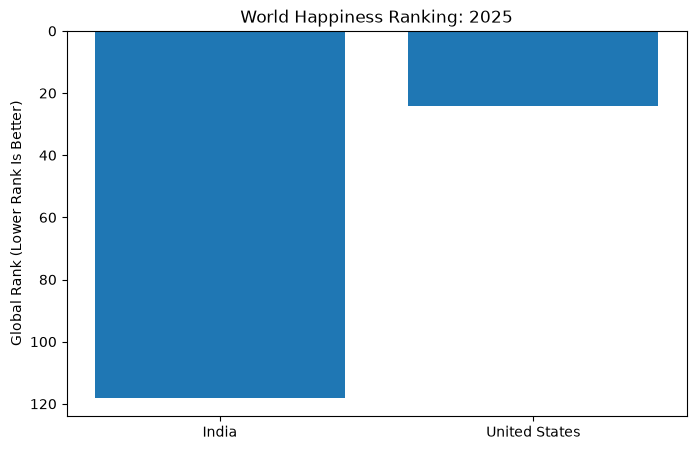

In [5]:
# 1. Inflation target comparison
plt.figure(figsize=(8, 5))
plt.bar(
    comparison_data["Country"],
    comparison_data["Inflation_Target_Percent"]
)
plt.title("India vs United States: Inflation Targets")
plt.ylabel("Inflation Target (%)")
plt.savefig(output_dir / "visualizations" / "inflation_target_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


# 2. Billionaire count comparison
comparison_data.set_index("Country")[
    ["Billionaires_2024", "Billionaires_2025"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Billionaire Count: India vs United States")
plt.ylabel("Number of Billionaires")
plt.xticks(rotation=0)
plt.savefig(output_dir / "visualizations" / "billionaire_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


# 3. Happiness ranking comparison
plt.figure(figsize=(8, 5))
plt.bar(
    comparison_data["Country"],
    comparison_data["Happiness_Rank_2025"]
)
plt.title("World Happiness Ranking: 2025")
plt.ylabel("Global Rank (Lower Rank Is Better)")
plt.gca().invert_yaxis()
plt.savefig(output_dir / "visualizations" / "happiness_ranking_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

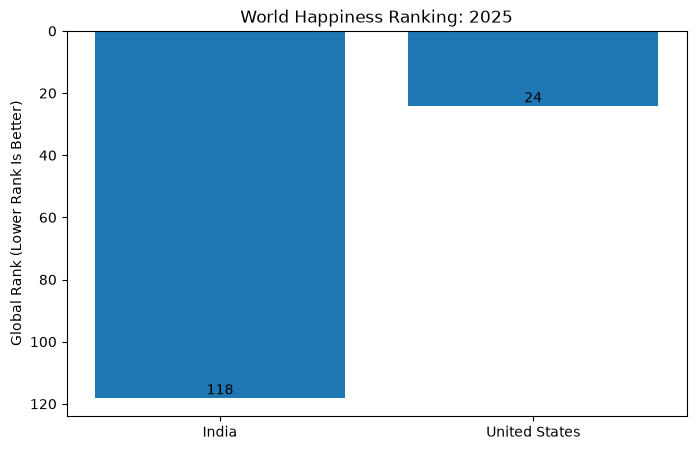

In [6]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    comparison_data["Country"],
    comparison_data["Happiness_Rank_2025"]
)

plt.title("World Happiness Ranking: 2025")
plt.ylabel("Global Rank (Lower Rank Is Better)")
plt.gca().invert_yaxis()

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height())}",
        ha="center",
        va="bottom"
    )

plt.savefig(
    output_dir / "visualizations" / "happiness_ranking_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:

import requests
import pandas as pd
import matplotlib.pyplot as plt

# World Bank CPI inflation indicator
indicator = "FP.CPI.TOTL.ZG"

def get_inflation_data(country_code):
    url = (
        f"https://api.worldbank.org/v2/country/{country_code}/"
        f"indicator/{indicator}?date=2000:2024&format=json&per_page=100"
    )

    response = requests.get(url, timeout=30)
    response.raise_for_status()
    records = response.json()[1]

    return pd.DataFrame([
        {
            "Year": int(item["date"]),
            "Inflation": item["value"]
        }
        for item in records
        if item["value"] is not None
    ])

india_inflation = get_inflation_data("IND")
us_inflation = get_inflation_data("USA")

india_inflation["Country"] = "India"
us_inflation["Country"] = "United States"

inflation_data = pd.concat(
    [india_inflation, us_inflation],
    ignore_index=True
)

inflation_data = inflation_data.sort_values(
    ["Year", "Country"]
).reset_index(drop=True)

display(inflation_data.head(10))
print("Total records:", len(inflation_data))
print("Missing values:\n", inflation_data.isnull().sum())


,Year,Inflation,Country
0,2000,4.009436,India
1,2000,3.376857,United States
2,2001,3.779293,India
3,2001,2.826171,United States
4,2002,4.297152,India
5,2002,1.586032,United States
6,2003,3.805859,India
7,2003,2.270095,United States
8,2004,3.767252,India
9,2004,2.677237,United States


Total records: 50
Missing values:
 Year         0
Inflation    0
Country      0
dtype: int64


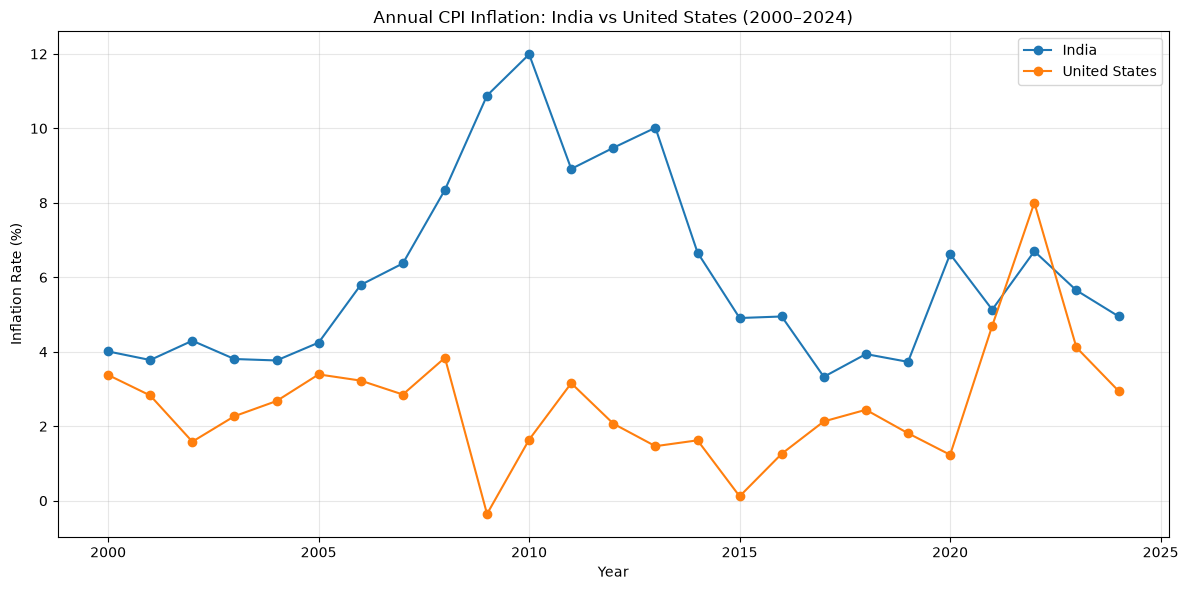

In [8]:
plt.figure(figsize=(12, 6))

for country in ["India", "United States"]:
    country_data = inflation_data[
        inflation_data["Country"] == country
    ]

    plt.plot(
        country_data["Year"],
        country_data["Inflation"],
        marker="o",
        label=country
    )

plt.title("Annual CPI Inflation: India vs United States (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Inflation Rate (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "visualizations" / "actual_inflation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
inflation_summary = (
    inflation_data.groupby("Country")["Inflation"]
    .agg(
        Average_Inflation="mean",
        Median_Inflation="median",
        Inflation_Volatility="std",
        Minimum_Inflation="min",
        Maximum_Inflation="max"
    )
    .round(2)
)

display(inflation_summary)

,Average_Inflation,Median_Inflation,Inflation_Volatility,Minimum_Inflation,Maximum_Inflation
Country,,,,,
India,6.09,5.13,2.49,3.33,11.99
United States,2.58,2.44,1.63,-0.36,8.00


In [10]:
# Save actual inflation data and summary
inflation_data.to_csv(
    output_dir / "data" / "processed" / "india_us_inflation_2000_2024.csv",
    index=False
)

inflation_summary.to_csv(
    output_dir / "data" / "processed" / "inflation_summary_india_us.csv"
)

print("Inflation datasets saved successfully!")

Inflation datasets saved successfully!


In [11]:
policy_comparison = pd.DataFrame({
    "Feature": [
        "Primary Objective",
        "Inflation Measure",
        "Inflation Target",
        "Main Policy Rate",
        "Decision Making Body",
        "Policy Framework"
    ],
    "India_RBI": [
        "Price stability with growth",
        "CPI",
        "4% (2%–6% band)",
        "Repo Rate",
        "Monetary Policy Committee",
        "Flexible Inflation Targeting"
    ],
    "United_States_Fed": [
        "Maximum employment and price stability",
        "PCE",
        "2% long-run goal",
        "Federal Funds Rate",
        "Federal Open Market Committee",
        "Dual Mandate"
    ]
})

display(policy_comparison)

policy_comparison.to_csv(
    output_dir / "data" / "processed" / "monetary_policy_comparison.csv",
    index=False
)

print("Monetary policy comparison saved successfully!")

,Feature,India_RBI,United_States_Fed
0,Primary Objective,Price stability with growth,Maximum employment and price stability
1,Inflation Measure,CPI,PCE
2,Inflation Target,4% (2%–6% band),2% long-run goal
3,Main Policy Rate,Repo Rate,Federal Funds Rate
4,Decision Making Body,Monetary Policy Committee,Federal Open Market Committee
5,Policy Framework,Flexible Inflation Targeting,Dual Mandate


Monetary policy comparison saved successfully!


In [14]:
from pathlib import Path

for folder in ["raw", "processed"]:
    path = output_dir / "data" / folder
    print(f"\n{folder.upper()} FILES:")
    for file in path.glob("*"):
        print(file.name)


RAW FILES:
inr_usd_annual_average_1971_1973.csv
inr_usd_fred_1973_2024.csv
inr_usd_historical_1947_1964.csv
inr_usd_transition_1971_1972.csv
r151_major_monetary_policy_rates_and_reserve_requirements_bank.csv

PROCESSED FILES:
historical_inr_usd_1947_1971.csv
india_us_inflation_2000_2024.csv
inflation_summary_india_us.csv
inr_usd_forecast_2026_2050.csv
monetary_policy_comparison.csv


In [13]:
forecast_file = output_dir / "data" / "processed" / "inr_usd_forecast_2026_2050.csv"

print("Forecast file exists:", forecast_file.exists())
print("Expected location:", forecast_file)


Forecast file exists: False
Expected location: C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis\data\processed\inr_usd_forecast_2026_2050.csv


In [15]:
visualization_dir = output_dir / "visualizations"

print("Visualization folder exists:", visualization_dir.exists())

for file in sorted(visualization_dir.glob("*.png")):
    print(file.name)

Visualization folder exists: True
actual_inflation_comparison.png
annual_exchange_rate.png
annual_inr_change.png
arima_actual_vs_predicted.png
billionaire_comparison.png
happiness_ranking_comparison.png
historical_inr_usd_1947_1971.png
inflation_target_comparison.png
inr_usd_forecast_2026_2050.png
monthly_exchange_rate.png
sarima_actual_vs_predicted.png
